<a href="https://colab.research.google.com/github/HollowInsideBro/cv-2026-Borisovskiy/blob/main/lab01/solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная 1. Среда, данные и первая сводка

Задание целиком: `labs/lab01/README.md` в репозитории курса.

Как работать с ноутбуком:
1. В первой ячейке впишите свой номер варианта.
2. Заполните ячейки с пометкой `TODO` по порядку. Подсказки в комментариях.
3. В конце выполните Run All с нуля, скачайте ноутбук и `results.zip`.

Ноутбук работает в Kaggle, Colab и локально. В Kaggle включите интернет: правая панель → Settings → Internet → On. Если интернет в Kaggle включить нельзя, работайте в Colab или локально.

## 0. Установка и загрузка данных

Ячейка определяет, где запущен ноутбук, находит или скачивает `get_data.py` из репозитория курса и загружает ваш вариант. Ничего в ней менять не нужно, кроме `VARIANT`.

In [33]:
VARIANT = 2   # TODO: ваш порядковый номер в списке группы, например 7
DATA_SOURCE = None  # запасной путь: папка с архивами variant_NN.zip

import os
import sys
import inspect
import urllib.request
import json
import hashlib
import shutil
import zipfile
from pathlib import Path

assert isinstance(VARIANT, int) and 0 <= VARIANT <= 22, "Впишите свой номер варианта: целое число от 1 до 22"
if VARIANT == 0:
    print("ВНИМАНИЕ: вариант 00 демонстрационный, работа на нём не засчитывается")

if "google.colab" in sys.modules:
    ENV, DATA_ROOT = "colab", Path("/content/data")
elif Path("/kaggle/working").exists():
    ENV, DATA_ROOT = "kaggle", Path("/kaggle/working/data")
elif Path("../../data/get_data.py").exists():
    # Ноутбук открыт прямо из клона репозитория курса: данные кладём в его папку data/
    ENV, DATA_ROOT = "local", Path("../../data").resolve()
else:
    # Локально: ноутбук лежит в cv-2026-familiya/lab01/, данные кладём в cv-2026-familiya/data/.
    # Эта папка указана в .gitignore, в репозиторий она не попадёт.
    ENV, DATA_ROOT = "local", Path("..").resolve() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("среда:", ENV, "| папка данных:", DATA_ROOT.name)

GET_DATA_URL = "https://raw.githubusercontent.com/ykvnkm/computer-vision-course/main/data/get_data.py"
course_copy = Path("../../data/get_data.py")
kaggle_copies = sorted(Path("/kaggle/input").glob("**/get_data.py")) if ENV == "kaggle" else []
if course_copy.exists():
    script_dir = course_copy.resolve().parent
elif kaggle_copies:
    # Kaggle с подключённым датасетом-зеркалом курса: интернет не нужен
    script_dir = kaggle_copies[0].parent
    print("get_data.py из подключённого датасета:", kaggle_copies[0])
else:
    script_dir = DATA_ROOT
    if not (script_dir / "get_data.py").exists():
        try:
            urllib.request.urlretrieve(GET_DATA_URL, script_dir / "get_data.py")
        except Exception as e:
            raise RuntimeError("Не удалось скачать get_data.py. В Kaggle включите Internet в Settings; "
                               "в остальных случаях проверьте подключение к сети.") from e
sys.path.insert(0, str(script_dir))
from get_data import ensure_variant

params = inspect.signature(ensure_variant).parameters
kwargs = {"dest": DATA_ROOT} if "dest" in params else {}
if DATA_SOURCE and "source" in params:
    kwargs["source"] = DATA_SOURCE
try:
    DATA_DIR = Path(ensure_variant(VARIANT, **kwargs))
except Exception:
    archive = DATA_ROOT / f"variant_{VARIANT:02d}.zip"
    from get_data import VARIANTS
    if not archive.is_file():
        raise
    digest = hashlib.sha256(archive.read_bytes()).hexdigest()
    if digest != VARIANTS[VARIANT]["zip_sha256"]:
        raise RuntimeError("SHA-256 архива варианта не совпал с опубликованным")
    DATA_DIR = DATA_ROOT / f"variant_{VARIANT:02d}"
    if DATA_DIR.is_dir():
        info = json.loads((DATA_DIR / "variant.json").read_text(encoding="utf-8"))
        if info.get("variant") != VARIANT or info.get("n_images") != VARIANTS[VARIANT]["n_images"] or len(list((DATA_DIR / "images").iterdir())) != VARIANTS[VARIANT]["n_images"]:
            raise RuntimeError("Распакованная папка не совпадает с вариантом")
    else:
        temporary = DATA_ROOT / f".variant_{VARIANT:02d}_verified"
        with zipfile.ZipFile(archive) as bundle:
            if bundle.testzip() is not None:
                raise RuntimeError("Архив варианта повреждён")
            for item in bundle.infolist():
                parts = Path(item.filename).parts
                if not parts or parts[0] != f"variant_{VARIANT:02d}" or ".." in parts or Path(item.filename).is_absolute():
                    raise RuntimeError("В архиве найден недопустимый путь")
            bundle.extractall(temporary)
        candidate = temporary / f"variant_{VARIANT:02d}"
        if not (candidate / "variant.json").is_file() or len(list((candidate / "images").iterdir())) != VARIANTS[VARIANT]["n_images"]:
            shutil.rmtree(temporary, ignore_errors=True)
            raise RuntimeError("Содержимое архива не прошло проверку варианта")
        shutil.move(str(candidate), str(DATA_DIR))
        shutil.rmtree(temporary, ignore_errors=True)
    print("Архив прошёл SHA-256; внутренний digest каталога в скрипте курса не совпал.")
print("данные варианта:", DATA_DIR.name)
print(sorted(p.name for p in DATA_DIR.iterdir()))

среда: colab | папка данных: data
Вариант 02 уже на месте: /content/data/variant_02
данные варианта: variant_02
['.get_data.json', 'README.md', 'annotations', 'images', 'labels.csv', 'variant.json']


In [34]:
import json
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image

IMG_DIR = DATA_DIR / "images"
XML_DIR = DATA_DIR / "annotations" / "xmls"
TRIMAP_DIR = DATA_DIR / "annotations" / "trimaps"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

print("OpenCV", cv2.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

OpenCV 5.0.0 | numpy 2.1.3 | pandas 2.2.3


## 1. Что лежит в папке варианта

Прочитайте `variant.json` и `labels.csv`. Проверьте, что номер варианта в `variant.json` совпадает с вашим.

In [35]:
variant_info = json.loads((DATA_DIR / "variant.json").read_text(encoding="utf-8"))
labels = pd.read_csv(DATA_DIR / "labels.csv")
assert int(variant_info["variant"]) == VARIANT, "Номер варианта в variant.json не совпадает"
print(json.dumps(variant_info, ensure_ascii=False, indent=2))
labels.head()

{
  "variant": 2,
  "dataset_version": "v1",
  "source": "release",
  "breeds": [
    "Birman",
    "Siamese",
    "basset_hound",
    "keeshond"
  ],
  "species": {
    "Birman": "cat",
    "Siamese": "cat",
    "basset_hound": "dog",
    "keeshond": "dog"
  },
  "class_ids": {
    "Birman": 0,
    "Siamese": 1,
    "basset_hound": 2,
    "keeshond": 3
  },
  "names_ru": {
    "Birman": "бирманская кошка (священная бирма)",
    "Siamese": "сиамская кошка",
    "basset_hound": "бассет-хаунд",
    "keeshond": "кеесхонд (вольфшпиц)"
  },
  "n_images": 800,
  "n_boxes": 400,
  "n_trimaps": 800,
  "per_breed": {
    "Birman": {
      "images": 200,
      "boxes": 100,
      "trimaps": 200
    },
    "Siamese": {
      "images": 200,
      "boxes": 100,
      "trimaps": 200
    },
    "basset_hound": {
      "images": 200,
      "boxes": 100,
      "trimaps": 200
    },
    "keeshond": {
      "images": 200,
      "boxes": 100,
      "trimaps": 200
    }
  },
  "dataset": "Oxford-IIIT Pet",

,filename,breed,species,class_id
0,basset_hound_1.jpg,basset_hound,dog,2
1,basset_hound_2.jpg,basset_hound,dog,2
2,basset_hound_3.jpg,basset_hound,dog,2
3,basset_hound_4.jpg,basset_hound,dog,2
4,basset_hound_5.jpg,basset_hound,dog,2


## 2. Изображение как массив

Возьмите одно изображение и посмотрите, что вернул OpenCV. Выберите файл, который Pillow определяет как `JPEG` в режиме `RGB`: необычные файлы разберём в разделе 3.

In [36]:
# Выбираем обычный цветной JPEG, чтобы различие BGR/RGB было заметным
best, best_score = None, -1.0
for fn in labels["filename"].sample(frac=1, random_state=0).head(100):
    with Image.open(IMG_DIR / fn) as im:
        if im.format != "JPEG" or im.mode != "RGB":
            continue
        arr = np.asarray(im.resize((64, 64)), dtype=np.float32)[16:48, 16:48]
    score = float(np.abs(arr[..., 0] - arr[..., 2]).mean())
    if score > best_score:
        best, best_score = fn, score
assert best is not None, "Не найдено обычное RGB JPEG изображение"
example_name = best
example_path = IMG_DIR / example_name
bgr = cv2.imread(str(example_path))
print("файл:", example_name)
print("type:", type(bgr), "| shape:", bgr.shape, "| dtype:", bgr.dtype, "| min:", bgr.min(), "| max:", bgr.max())
print("пиксель в центре (BGR):", bgr[bgr.shape[0] // 2, bgr.shape[1] // 2])

файл: basset_hound_56.jpg
type: <class 'numpy.ndarray'> | shape: (331, 500, 3) | dtype: uint8 | min: 0 | max: 255
пиксель в центре (BGR): [224 230 237]


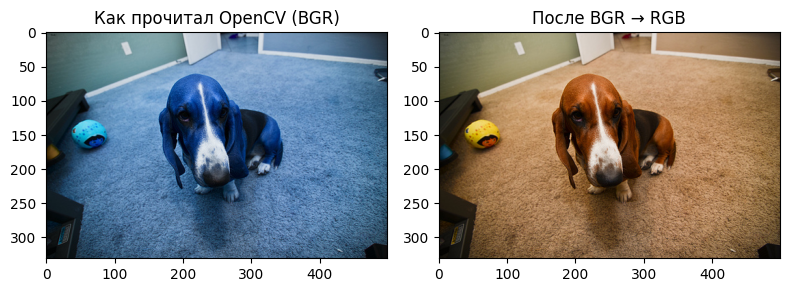

пиксель в центре (RGB): [237 230 224]


In [37]:
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1); plt.imshow(bgr); plt.title("Как прочитал OpenCV (BGR)")
plt.subplot(1, 2, 2); plt.imshow(rgb); plt.title("После BGR → RGB")
plt.tight_layout()
plt.show()
print("пиксель в центре (RGB):", rgb[rgb.shape[0] // 2, rgb.shape[1] // 2])

Преобразования. Подсказки:

| Что | Функция |
|---|---|
| оттенки серого | `cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)` |
| ресайз | `cv2.resize(rgb, (224, 224))` |
| отражение | `cv2.flip(rgb, 1)` |

In [38]:
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
resized = cv2.resize(rgb, (224, 224))
flipped = cv2.flip(rgb, 1)
print("gray:", gray.shape, "| resized:", resized.shape, "| flipped:", flipped.shape)

gray: (331, 500) | resized: (224, 224, 3) | flipped: (331, 500, 3)


In [39]:
# Ловушка uint8: запустите и посмотрите, что получилось
a = np.array([[50, 200, 250]], dtype=np.uint8)   # «картинка» 1x3 пикселя
print("numpy a + 100:", a + 100)
print("cv2.add:      ", cv2.add(a, np.full_like(a, 100)))

numpy a + 100: [[150  44  94]]
cv2.add:       [[150 255 255]]


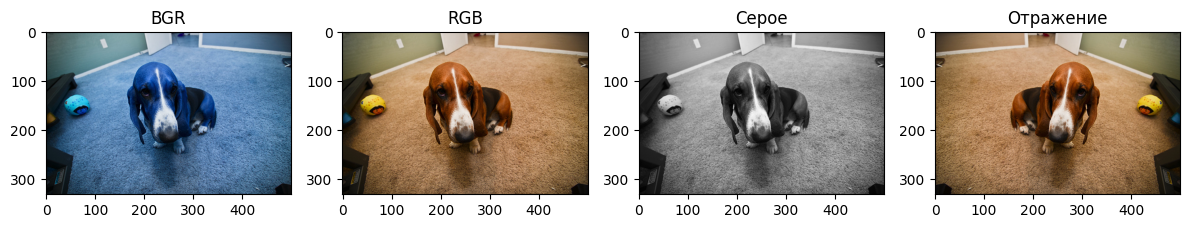

In [40]:
plt.figure(figsize=(12, 3))
plt.subplot(1, 4, 1); plt.imshow(bgr); plt.title("BGR")
plt.subplot(1, 4, 2); plt.imshow(rgb); plt.title("RGB")
plt.subplot(1, 4, 3); plt.imshow(gray, cmap="gray"); plt.title("Серое")
plt.subplot(1, 4, 4); plt.imshow(flipped); plt.title("Отражение")
plt.tight_layout()
plt.savefig(RESULTS / "transforms.png", dpi=110, bbox_inches="tight")
plt.show()

## 3. Сводка по датасету

Пройдите по всем файлам в `images/`. Для каждого соберите словарь и добавьте в список `rows`.

`Image.open(p)` из Pillow честно говорит формат (`.format`) и режим (`.mode`: `RGB`, `L`, `RGBA`, `P`). `cv2.imread(p)` по умолчанию всегда отдаёт 3 канала и такие файлы не выдаст.

In [41]:
label_by_file = labels.set_index("filename")

rows = []
for p in sorted(IMG_DIR.iterdir()):
    if p.name.startswith(".") or not p.is_file():
        continue
    rec = {"filename": p.name, "ext": p.suffix.lower()}
    with Image.open(p) as im:
        rec.update({"pil_format": im.format, "mode": im.mode,
                    "width": im.width, "height": im.height})
    rec["has_xml"] = (XML_DIR / (p.stem + ".xml")).exists()
    lab = label_by_file.loc[p.name]
    rec["breed"] = lab["breed"]
    rec["species"] = lab["species"]
    rows.append(rec)

info = pd.DataFrame(rows)
info.head()

,filename,ext,pil_format,mode,width,height,has_xml,breed,species
0,Birman_1.jpg,.jpg,JPEG,RGB,375,500,False,Birman,cat
1,Birman_10.jpg,.jpg,JPEG,RGB,500,330,True,Birman,cat
2,Birman_100.jpg,.jpg,JPEG,RGB,500,334,True,Birman,cat
3,Birman_101.jpg,.jpg,JPEG,RGB,500,375,True,Birman,cat
4,Birman_102.jpg,.jpg,JPEG,RGB,332,500,True,Birman,cat


In [42]:
n_breeds = int(info["breed"].nunique())
breed_species = info[["breed", "species"]].drop_duplicates()
breed_counts = info["breed"].value_counts()
summary = {
    "variant": VARIANT,
    "n_files": int(len(info)),
    "n_breeds": n_breeds,
    "n_cat_breeds": int((breed_species["species"] == "cat").sum()),
    "n_dog_breeds": int((breed_species["species"] == "dog").sum()),
    "n_cat_images": int((info["species"] == "cat").sum()),
    "n_dog_images": int((info["species"] == "dog").sum()),
    "width_min": int(info["width"].min()),
    "width_median": float(info["width"].median()),
    "width_max": int(info["width"].max()),
    "height_min": int(info["height"].min()),
    "height_median": float(info["height"].median()),
    "height_max": int(info["height"].max()),
    "n_non_rgb": int((info["mode"] != "RGB").sum()),
    "n_jpg_not_jpeg": int(((info["ext"] == ".jpg") & (info["pil_format"] != "JPEG")).sum()),
    "n_with_xml": int(info["has_xml"].sum()),
    "breed_counts": "; ".join(f"{k}: {int(v)}" for k, v in breed_counts.sort_index().items()),
}
summary_df = pd.DataFrame(list(summary.items()), columns=["metric", "value"])
summary_df.to_csv(RESULTS / "summary.csv", index=False)
summary_df

,metric,value
0,variant,2
1,n_files,800
2,n_breeds,4
3,n_cat_breeds,2
4,n_dog_breeds,2
5,n_cat_images,400
6,n_dog_images,400
7,width_min,183
8,width_median,500.0
9,width_max,679


### Проблемные файлы

Найдите файлы, которые сломают обучение в следующих лабах: режим не `RGB` или формат не совпадает с расширением. Для одного такого файла сравните `cv2.imread(p).shape` и `cv2.imread(p, cv2.IMREAD_UNCHANGED).shape`.

In [43]:
ext_for_format = {"JPEG": {".jpg", ".jpeg"}, "PNG": {".png"}, "BMP": {".bmp"}, "TIFF": {".tif", ".tiff"}, "GIF": {".gif"}}
non_rgb = info.loc[info["mode"] != "RGB", ["filename", "mode", "pil_format"]]
mismatch = info.loc[info.apply(lambda r: r["ext"] not in ext_for_format.get(r["pil_format"], {r["ext"]}), axis=1),
                    ["filename", "ext", "pil_format"]]
print("Не в RGB:", len(non_rgb)); display(non_rgb)
print("Формат не совпадает с расширением:", len(mismatch)); display(mismatch)

Не в RGB: 0


,filename,mode,pil_format


Формат не совпадает с расширением: 0


,filename,ext,pil_format


In [44]:
problem_names = list(non_rgb["filename"]) + list(mismatch["filename"])
if problem_names:
    problem_path = IMG_DIR / problem_names[0]
else:
    problem_path = IMG_DIR / labels.iloc[0]["filename"]
    print("Проблемных файлов нет; сравниваю обычное RGB-изображение.")
default_read = cv2.imread(str(problem_path))
unchanged_read = cv2.imread(str(problem_path), cv2.IMREAD_UNCHANGED)
print(problem_path.name)
print("cv2.imread:", None if default_read is None else default_read.shape)
print("IMREAD_UNCHANGED:", None if unchanged_read is None else unchanged_read.shape)

Проблемных файлов нет; сравниваю обычное RGB-изображение.
basset_hound_1.jpg
cv2.imread: (333, 500, 3)
IMREAD_UNCHANGED: (333, 500, 3)


## 4. Разметка и сетка примеров

- XML в формате Pascal VOC: внутри `<object><bndbox>` координаты `xmin, ymin, xmax, ymax`. Есть не у всех изображений, иногда объектов два.
- Trimap: PNG того же размера, что и фото. 1 = животное, 2 = фон, 3 = граница.

In [45]:
def read_boxes(xml_path):
    root = ET.parse(xml_path).getroot()
    boxes = []
    for obj in root.findall("object"):
        box = obj.find("bndbox")
        if box is not None:
            boxes.append(tuple(int(float(box.findtext(key))) for key in ("xmin", "ymin", "xmax", "ymax")))
    return boxes

xml_candidates = sorted(XML_DIR.glob("*.xml"))
assert xml_candidates, "XML-разметка не найдена"
sample_xml = xml_candidates[0]
sample_stem = sample_xml.stem
print(sample_xml.name, read_boxes(sample_xml))
trimap = cv2.imread(str(TRIMAP_DIR / (sample_stem + ".png")), cv2.IMREAD_UNCHANGED)
assert trimap is not None, f"Не найдена trimap для {sample_stem}"
print("trimap unique values:", np.unique(trimap))

Birman_10.xml [(45, 103, 194, 225)]
trimap unique values: [1 2 3]


Сетка: по одному фото каждой породы с боксом головы. Бокс рисуется так: `cv2.rectangle(rgb, (x0, y0), (x1, y1), (0, 255, 0), 3)`. Берите фото, у которых есть XML.

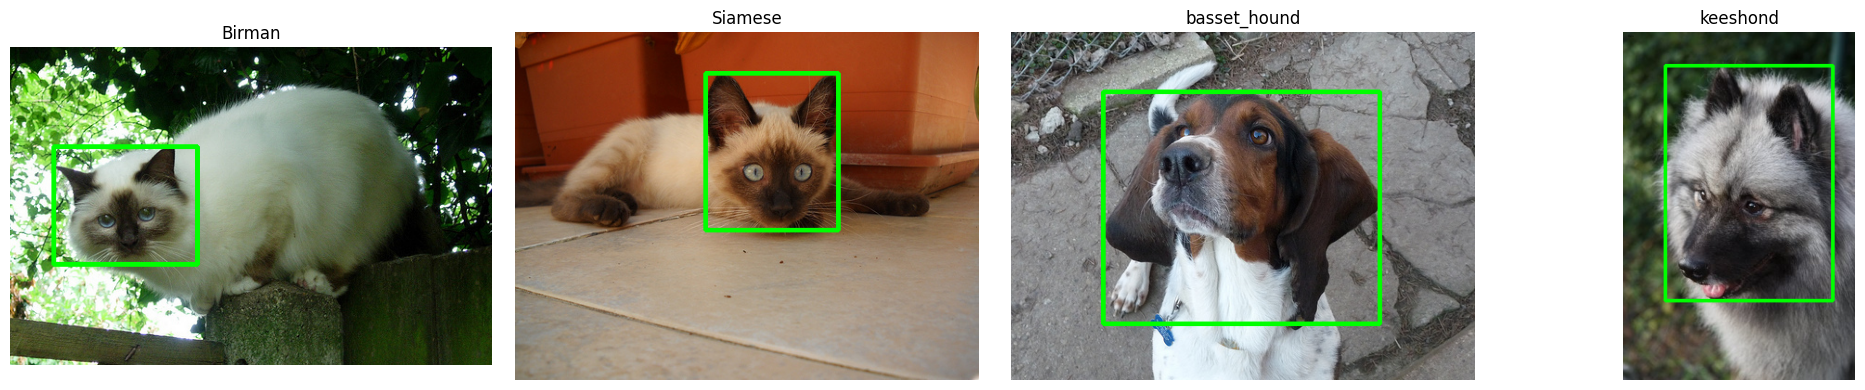

In [46]:
breed_order = list(variant_info["breeds"])
fig, axes = plt.subplots(1, len(breed_order), figsize=(5 * len(breed_order), 4))
if len(breed_order) == 1:
    axes = [axes]
for ax, breed in zip(axes, breed_order):
    candidates = labels[(labels["breed"] == breed) & labels["filename"].map(
        lambda name: (XML_DIR / (Path(name).stem + ".xml")).exists())]
    assert len(candidates), f"Для породы {breed} не найдено изображение с XML"
    row = candidates.sort_values("filename").iloc[0]
    path = IMG_DIR / row["filename"]
    image = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
    boxes = read_boxes(XML_DIR / (path.stem + ".xml"))
    for x0, y0, x1, y1 in boxes:
        cv2.rectangle(image, (x0, y0), (x1, y1), (0, 255, 0), 3)
    ax.imshow(image); ax.set_title(breed); ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS / "samples_grid.png", dpi=110, bbox_inches="tight")
plt.show()

## 5. Числа для отчёта и выгрузка

Напечатайте всё, что понадобится в README. Затем упакуйте `results/` в архив и скачайте:
- в Kaggle: правая панель → Output → `results.zip` → Download; ноутбук: File → Download Notebook;
- в Colab: архив скачается сам после запуска ячейки; ноутбук: File → Download → Download .ipynb;
- локально: ничего скачивать не нужно, всё уже лежит в папке `lab01/`.

Переименуйте скачанный ноутбук в `solution.ipynb`.

In [47]:
print(summary_df.to_string(index=False))
expected = {"summary.csv", "transforms.png", "samples_grid.png"}
missing = expected - {p.name for p in RESULTS.iterdir()}
print("не хватает:", missing if missing else "ничего, все 3 файла на месте")

        metric                                                       value
       variant                                                           2
       n_files                                                         800
      n_breeds                                                           4
  n_cat_breeds                                                           2
  n_dog_breeds                                                           2
  n_cat_images                                                         400
  n_dog_images                                                         400
     width_min                                                         183
  width_median                                                       500.0
     width_max                                                         679
    height_min                                                         200
 height_median                                                       375.0
    height_max           

In [48]:
import shutil
if ENV != "local":
    archive = shutil.make_archive("results", "zip", RESULTS)
    print("архив:", archive)
    if ENV == "colab":
        from google.colab import files
        files.download(archive)

архив: /content/results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>